# CB2330 HT26 Project: Neuropixels 
### Authors: Emilis Skruodys and Simran Swain
-------

## Project overview

- **Paper:** *Fully integrated silicon probes for high-density recording of neural activity*, Jun et al. (2017) – [Nature link](https://www.nature.com/articles/nature24636)
- **What the paper does:** Tests Neuropixels, a silicon probe that records neural activity at high spatiotemporal resolution and with large-volume coverage in freely moving animals.
- **Data object:** Detected neurons at individual Neuropixels recording sites.
- **Random variable:** Number of neurons observed at one recording site.
- **Question:** The paper reports 6.9 ± 5.1 neurons producing a signal per recording site at a single time. Can a simple mathematical model explain this mean and the large spread?

## Workflow 

| Section | Purpose |
|---|---|
| **0. Setup** | Import the libraries |
| **1. Parameters and assumptions** | Fix the constants and state what the model assumes |
| **2. Forward** | Assume θ = 6.9 and simulate what the model predicts |
| **3. Backwards** | Estimate θ from the paper's mean (3.1, 3.2) and SD (3.3) |
| **4. Comments** | What the model adds, and where it breaks |

## 0. Setup

In [1]:
import math
import matplotlib.pyplot as plt

## 1. Parameters and assumptions

**θ** is the expected number of detectable neurons per recording site. The model assumes that:

- every recording site shares the same θ,
- neurons are detected independently of each other,
- there is no distinction between brain regions or recording depths,
- the paper's ± 5.1 is a standard deviation across sites,
- only summary statistics (mean and SD) are available, not the raw counts per site.

We define the random variable

$$
X_i = \text{number of detectable neurons at recording site } i
$$

and assume

$$
X_i \mid \theta \sim \mathrm{Poisson}(\theta).
$$

The Poisson probability function is

$$
P(X_i=k\mid\theta)
=
\frac{e^{-\theta}\theta^k}{k!},
\qquad k=0,1,2,\ldots
$$

For a Poisson distribution,

$$
E[X_i]=\theta,
\qquad
\mathrm{Var}(X_i)=\theta,
\qquad
SD(X_i)=\sqrt{\theta}.
$$

In [2]:
# Model parameters
theta = 6.9           # expected number of events (detected neurons) per site
k = range(31)         # possible neuron counts at one site (0 to 30)
n_sites = 3898        # sites recorded in one experiment, across all brain regions
n_simulations = 1000  # how many times we repeat the whole experiment

# Random number generator (linear congruential generator, LCG) parameters
seed = 12345          # start value, fixed so that results are reproducible
a = 1664525           # LCG multiplier
c = 1013904223        # LCG increment
m = 2**32             # LCG modulus

## 2. Forward

**Goal:** Assume the paper's θ = 6.9 neurons/site is correct and see what the model predicts.

**Generative model:** A Poisson model simulated with Monte Carlo. Poisson is a natural choice because each site's count is the sum of many small, independent chances of detecting a neuron.

We simulate neuron counts at many recording sites, repeat the experiment many times, and compare the simulated mean and SD with the paper's.

For the forward model, we fix the parameter using the paper's reported mean:

$$
\theta = 6.9.
$$

Therefore,

$$
X_i \sim \mathrm{Poisson}(6.9),
\qquad i=1,\ldots,3898.
$$

The theoretical standard deviation predicted by the model is

$$
SD(X)=\sqrt{\theta}
=\sqrt{6.9}
\approx 2.63.
$$

### 2.1. Poisson model functions

In [3]:
# Poisson model (theoretical curve)
def poisson(theta, k):
    """Probability P(X = x | theta) of seeing exactly x events, for every x in k."""
    poisson_results = []

    for x in k:
        result = ((theta ** x) * math.exp(-theta)) / math.factorial(x)
        poisson_results.append(result)

    return poisson_results


# Random number generator (LCG)
def random_number(seed, a, c, m):
    """Gives the new seed and a random number between 0 and 1."""
    seed = (a * seed + c) % m   # scramble the old seed into a new one
    r = seed / m                # squash it into the range 0 to 1
    return seed, r


# Poisson sampler
def poisson_random(theta, seed, a, c, m):
    """Makes one random Poisson count."""
    L = math.exp(-theta)   # threshold
    k = 0                  # number of random numbers used so far
    p = 1.0                # running product

    while p > L:
        seed, r = random_number(seed, a, c, m)
        k = k + 1
        p = p * r

    return k - 1, seed     # minus one, because the last multiplication overshoots


# Standard deviation
def standard_deviation(data):
    """How spread out the numbers in a list are."""
    mu = sum(data) / len(data)

    total = 0
    for x in data:
        total = total + (x - mu) ** 2   # squared distance from the mean

    variance = total / (len(data) - 1)  # n - 1 gives the sample variance
    return math.sqrt(variance)

### 2.2. Theoretical Poisson distribution

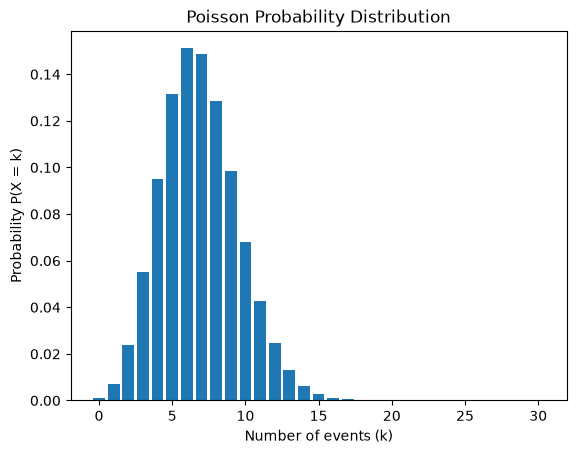

In [4]:
# Plot the Poisson distribution
poisson_results = poisson(theta, k)

plt.bar(k, poisson_results)
plt.xlabel("Number of events (k)")
plt.ylabel("Probability P(X = k)")
plt.title("Poisson Probability Distribution")
plt.show()

**Result:** The distribution peaks around 6–7 neurons and has a narrow spread, with almost no probability beyond 15.

### 2.3. Monte Carlo simulation

**Goal:** Simulate one experiment of 3,898 sites, record its SD, and repeat 1,000 times. Then compare the average simulated SD with the theoretical SD of a Poisson distribution, √θ.

For each simulated experiment, the sample mean and standard deviation are

$$
\bar{X}
=
\frac{1}{N}\sum_{i=1}^{N}X_i
$$

and

$$
s
=
\sqrt{
\frac{1}{N-1}
\sum_{i=1}^{N}(X_i-\bar{X})^2
}.
$$

We repeat the experiment $R=1000$ times and calculate the average simulated SD:

$$
\overline{s}_{MC}
=
\frac{1}{R}\sum_{r=1}^{R}s_r.
$$

In [5]:
# Monte Carlo simulation
simulated_sds = []

for i in range(n_simulations):
    simulated_data = []   # one simulated experiment

    for j in range(n_sites):
        value, seed = poisson_random(theta, seed, a, c, m)   # one simulated recording site
        simulated_data.append(value)

    simulated_sds.append(standard_deviation(simulated_data))   # spread of this experiment

print("Mean simulated SD:", sum(simulated_sds) / len(simulated_sds))
print("Theoretical SD:   ", math.sqrt(theta))

Mean simulated SD: 2.6273153802800735
Theoretical SD:    2.6267851073127395


**Conclusion:** Mean simulated SD (2.627) and theoretical SD (2.627) match, so the random generator and sampler produce a Poisson distribution with the right spread. However, neither matches the paper's reported SD of 5.1.

## 3. Backwards

**Goal:** Work backwards from the paper's results to find the θ the model would need. We try three ways:

1. Maximum likelihood (matching the mean) - **3.1**,
2. Monte Carlo (matching the mean) - **3.2**,
3. Monte Carlo (matching the SD) - **3.3** .

### 3.1. Maximum likelihood estimation (using negative log-likelihood)

**Goal:** Find the θ that makes the paper's mean of 6.9 most probable, by minimising the negative log-likelihood (NLL) over a grid of θ values.

For independent Poisson observations, the likelihood is

$$
L(\theta)
=
\prod_{i=1}^{N}
\frac{e^{-\theta}\theta^{x_i}}{x_i!}.
$$

Taking the negative logarithm gives

$$
NLL(\theta)
=
N\theta
-
\left(\sum_{i=1}^{N}x_i\right)\log(\theta)
+
\sum_{i=1}^{N}\log(x_i!).
$$

Because the final term does not depend on $\theta$, it can be removed when finding the minimum. Since the raw site counts are unavailable and the paper reports $\bar{x}=6.9$,

$$
\sum_{i=1}^{N}x_i=N\bar{x}.
$$

Therefore, the NLL used in our code is

$$
NLL^*(\theta)
=
N\theta-N\bar{x}\log(\theta).
$$

The maximum-likelihood estimate is

$$
\hat{\theta}
=
\underset{\theta}{\arg\min}\;NLL^*(\theta).
$$

For the paper's mean,

$$
\hat{\theta}=6.9.
$$

In [6]:
# Observation from the paper: mean number of neurons detected per site
mu = 6.9

In [7]:
# Negative log-likelihood (NLL) of theta given the paper's mean
def nll(theta):
    """Lower NLL = the observed mean is more likely under this theta."""
    if theta <= 0:
        return float('inf')  # theta <= 0 would mean zero or negative neurons, which is not valid

    # Poisson NLL summed over all sites; the log(k!) term is dropped because it does not depend on theta
    total = n_sites * theta
    total = total - n_sites * mu * math.log(theta)
    return total


# Grid search for the theta that minimises the NLL
theta_list = []
nll_list = []
theta = 0.0   # start at 0, since some sites detected 0 neurons in the paper

# We search up to theta = 20 to allow for more neurons being detected per site
while theta <= 20.0:
    theta_list.append(theta)
    nll_list.append(nll(theta))
    theta = theta + 0.1

# Pick the theta with the smallest NLL
min_nll = nll_list.index(min(nll_list))
theta_hat = theta_list[min_nll]

# Results
print("θ̂:", round(theta_hat, 2), "neurons/recording site")
print("minimum nll:", min(nll_list))

θ̂: 6.9 neurons/recording site
minimum nll: -25054.386190762358


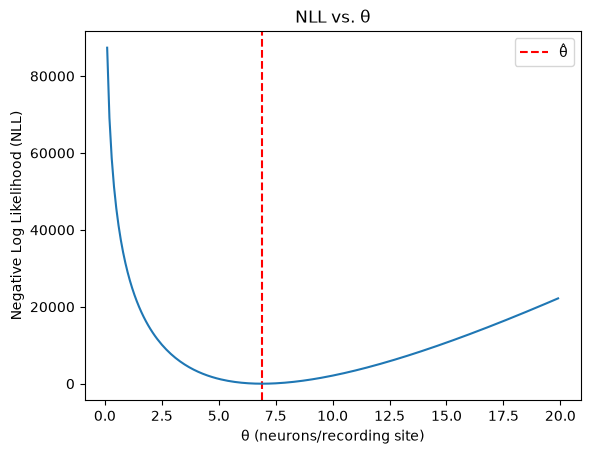

In [8]:
# Plot the NLL, shifted so that its minimum sits at zero
nll_shifted = []
min_nll = min(nll_list)

for i in nll_list:
    nll_shifted.append(i - min_nll)

plt.axvline(theta_hat, color='r', linestyle='--', label='θ̂')

plt.plot(theta_list, nll_shifted)
plt.xlabel("θ (neurons/recording site)")
plt.ylabel("Negative Log Likelihood (NLL)")
plt.title("NLL vs. θ")
plt.legend()
plt.show()

**Conclusion:** θ̂ = 6.9. This is expected, since for a Poisson distribution the best estimate of θ is the sample mean. The NLL confirms it rather than assuming it.

### 3.2. Monte Carlo parameter estimation

#### Matching the mean

**Goal:** Estimate θ by brute-force simulation. Simulate an experiment for each candidate θ and keep the one whose simulated mean is closest to 6.9.

For every candidate value of $\theta$, we simulate an experiment and calculate its mean,

$$
\bar{X}_{sim}(\theta)
=
\frac{1}{N}\sum_{i=1}^{N}X_i.
$$

We estimate $\theta$ by choosing the candidate that minimises the difference from the paper's mean:

$$
\hat{\theta}_{mean}
=
\underset{\theta}{\arg\min}
\left|
\bar{X}_{sim}(\theta)-6.9
\right|.
$$

In [9]:
# Observations from the paper (re-stated here for clarity)
n_sites = 3898
mu = 6.9

In [10]:
# Candidate thetas from 0.1 to 35.0 in steps of 0.1
# (we start at 0.1 because theta = 0.0 returns an error, even though some sites detected 0 neurons in the paper)
theta_candidates = []
candidate = 0.1

while candidate <= 35.0:
    theta_candidates.append(candidate)
    candidate = candidate + 0.1

# Simulate one experiment per candidate and store its mean and SD
simulated_means = []
simulated_sds = []

for candidate in theta_candidates:
    simulated_data = []

    for site in range(n_sites):
        value, seed = poisson_random(candidate, seed, a, c, m)
        simulated_data.append(value)

    # Mean of the simulated experiment
    simulated_mean = sum(simulated_data) / len(simulated_data)
    simulated_means.append(simulated_mean)

    # Standard deviation of the simulated experiment
    simulated_sd = standard_deviation(simulated_data)
    simulated_sds.append(simulated_sd)

In [11]:
# Find the theta whose simulated mean is closest to the paper's mean (6.9 neurons/site)
errors = []

for simulated_mean in simulated_means:
    error = abs(simulated_mean - mu)
    errors.append(error)

# theta hat = the candidate with the smallest error
min_error = errors.index(min(errors))
theta_hat = theta_candidates[min_error]

# Results
print("θ̂:", round(theta_hat, 2), "neurons/recording site")
print("Simulated mean:", simulated_means[min_error])
print("Simulated SD:", simulated_sds[min_error])

θ̂: 6.9 neurons/recording site
Simulated mean: 6.9035402770651615
Simulated SD: 2.5699219104196076


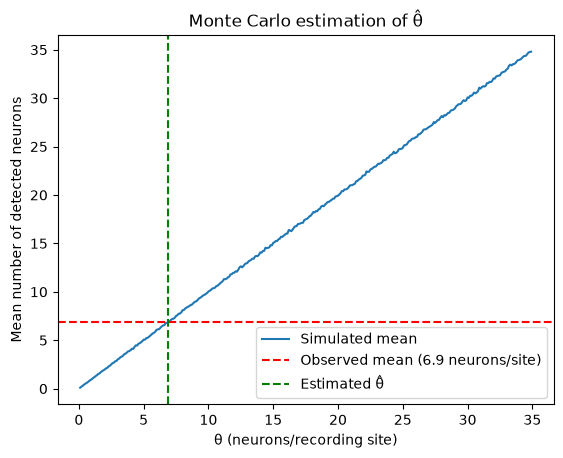

In [12]:
# Plot simulated mean against theta
plt.plot(theta_candidates, simulated_means, label='Simulated mean')
plt.axhline(mu, color='r', linestyle='--', label='Observed mean (6.9 neurons/site)')
plt.axvline(theta_hat, color='g', linestyle='--', label='Estimated θ̂')

plt.xlabel("θ (neurons/recording site)")
plt.ylabel("Mean number of detected neurons")
plt.title('Monte Carlo estimation of θ̂')
plt.legend()
plt.show()

**Conclusion:** θ̂ = 6.9 again, this time found by repeated simulated guessing rather than a formula. The two methods arrive at the same θ independently.

### 3.3. Standard deviation estimation

**Goal:** Ask which θ reproduces the paper's SD of 5.1 instead of its mean, reusing the simulated SDs from 3.2.

For each candidate $\theta$, let

$$
s_{sim}(\theta)
$$

be the standard deviation of the simulated experiment.

We choose

$$
\hat{\theta}_{SD}
=
\underset{\theta}{\arg\min}
\left|
s_{sim}(\theta)-5.1
\right|.
$$

This gives approximately

$$
\hat{\theta}_{SD}\approx26.
$$

This result is consistent with the theoretical Poisson relationship

$$
SD=\sqrt{\theta},
$$

because

$$
\theta\approx SD^2=5.1^2=26.01.
$$

In [13]:
sd = 5.1   # standard deviation of observed neurons per site (from the paper)

# Find the theta whose simulated SD is closest to the paper's SD
sd_error = []

for simulated_sd in simulated_sds:
    error = abs(simulated_sd - sd)
    sd_error.append(error)

min_error_sd = sd_error.index(min(sd_error))
theta_hat_sd = theta_candidates[min_error_sd]

# Results
print("θ̂ (from SD):", round(theta_hat_sd, 2), "neurons/recording site")
print("Simulated SD:", simulated_sds[min_error_sd])
print("Simulated mean:", simulated_means[min_error_sd])

θ̂ (from SD): 26.2 neurons/recording site
Simulated SD: 5.10172031461021
Simulated mean: 26.263981528989227


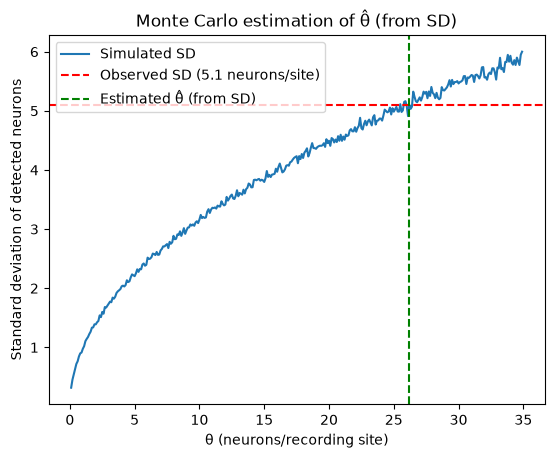

In [14]:
# Plot simulated SD against theta
plt.plot(theta_candidates, simulated_sds, label='Simulated SD')
plt.axhline(sd, color='r', linestyle='--', label='Observed SD (5.1 neurons/site)')
plt.axvline(theta_hat_sd, color='g', linestyle='--', label='Estimated θ̂ (from SD)')

plt.xlabel("θ (neurons/recording site)")
plt.ylabel("Standard deviation of detected neurons")
plt.title('Monte Carlo estimation of θ̂ (from SD)')
plt.legend()
plt.show()

**Conclusion:** A θ of about 26 is needed to reproduce the paper's SD of 5.1, but that θ would predict a mean of about 26 neurons per site instead of 6.9.

### 3.4. Uncertainty in $\hat{\theta}$

**Goal:** Estimate how much our fitted $\hat{\theta}$ would vary if the same experiment were repeated.

For a Poisson model, the maximum-likelihood estimate of $\theta$ is the sample mean:

$$
\hat{\theta} = \bar{X}
= \frac{1}{N}\sum_{i=1}^{N}X_i.
$$

We therefore use a **parametric Monte Carlo uncertainty test**:

1. Assume the fitted value $\hat{\theta}=6.9$ is the underlying parameter.
2. Simulate a new experiment containing $N=3898$ recording sites.
3. Re-estimate $\theta$ from that experiment using its sample mean.
4. Repeat this 1000 times.

This produces a distribution of estimates

$$
\hat{\theta}^{(1)},\hat{\theta}^{(2)},\ldots,\hat{\theta}^{(1000)}.
$$

We use the central 95% of these simulated estimates as an approximate uncertainty interval for $\hat{\theta}$.

In [15]:
# uncertainty in theta_hat using repeated Monte Carlo experiments
theta_fit = 6.9
n_uncertainty = 1000
seed_uncertainty = 54321   # separate seed so this is reproducible

theta_hat = []

for simulation in range(n_uncertainty):

    total_count = 0

    # we simulate one complete experiment
    for site in range(n_sites):
        value, seed_uncertainty = poisson_random(
            theta_fit, seed_uncertainty, a, c, m
        )
        total_count = total_count + value

    # for our Poisson model, theta_hat = sample mean
    theta_hat_sim = total_count / n_sites
    theta_hat.append(theta_hat_sim)


# mean and SD of the fitted theta values
mean = sum(theta_hat) / len(theta_hat)
sd = standard_deviation(theta_hat)

# approximate 95% Monte Carlo interval
sorted_theta = sorted(theta_hat)

lower_index = int(0.025 * n_uncertainty)
upper_index = int(0.975 * n_uncertainty) - 1

lower_95 = sorted_theta[lower_index]
upper_95 = sorted_theta[upper_index]

print("Mean θ̂:", mean)
print("SD of θ̂:", sd)
print("Approximate 95% interval:", lower_95, "to", upper_95)

Mean θ̂: 6.899845561826578
SD of θ̂: 0.041982846370005815
Approximate 95% interval: 6.8181118522319135 to 6.979733196511031


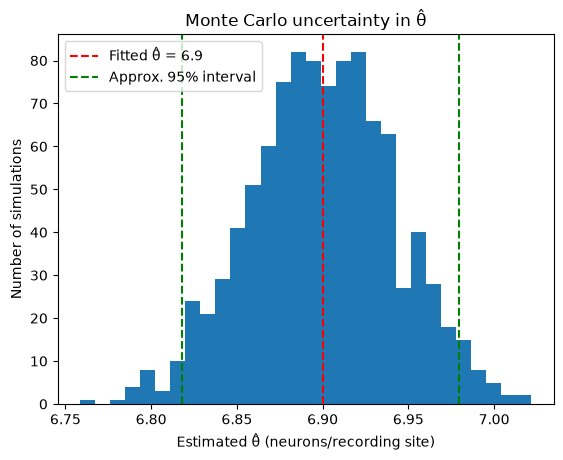

In [16]:
plt.hist(theta_hat, bins=30)

plt.axvline(theta_fit, color='r', linestyle='--',
            label='Fitted θ̂ = 6.9')

plt.axvline(lower_95, color='g', linestyle='--',
            label='Approx. 95% interval')

plt.axvline(upper_95, color='g', linestyle='--')

plt.xlabel("Estimated θ̂ (neurons/recording site)")
plt.ylabel("Number of simulations")
plt.title("Monte Carlo uncertainty in θ̂")
plt.legend()
plt.show()

**Conclusion:** The estimated $\hat{\theta}$ stays very close to 6.9 across the repeated simulations ($SD \approx 0.04$, 95% interval $6.82$–$6.98$), showing that the estimate of the mean is very stable, while the much larger SD reported in the paper suggests that the Poisson model is missing important variation in the real recordings.

## 3.5. Summary of the backwards fits

| Fitted to | $\hat{\theta}$ | Predicted value of the other statistic |
|---|---:|---|
| Mean (6.9) | 6.9 | SD $\approx$ 2.6 (paper: 5.1) |
| SD (5.1) | $\approx$ 26 | Mean $\approx$ 26 (paper: 6.9) |

**Conclusion:** The two fits require very different values of $\theta$:

$$
\hat{\theta}_{mean} \approx 6.9
\qquad \text{but} \qquad
\hat{\theta}_{SD} \approx 26.
$$

Therefore, no single Poisson parameter can reproduce both the mean and SD reported in the paper.

For a Poisson distribution,

$$
\frac{\mathrm{Var}(X)}{E[X]} = 1.
$$

For the paper's reported values,

$$
\frac{5.1^2}{6.9} \approx 3.77.
$$

The observed variance is therefore about 3.8 times larger than expected relative to the mean. This shows that the data are **overdispersed** compared with our simple Poisson model, so the observed variation cannot be explained by Poisson counting noise alone.


## 4. Comments

### What the model adds to the paper

Our model tests whether one constant detection rate, $\theta$, can explain the number of detectable neurons across recording sites. The model reproduces the paper's mean of 6.9, but predicts an SD of only about 2.6 compared with the reported SD of 5.1. This shows that the average neuron count can be explained by the simple model, but the much larger site-to-site variation cannot.

### Model limitations and why it breaks

The main limitation is the assumption that every recording site has the same $\theta$ and behaves independently. The larger spread in the paper suggests that these assumptions are too simple.

Possible explanations are:

- **Pooled brain regions:** The paper averages over regions with different neuron densities, which a single θ ignores.

- **Shared detections:** One neuron can be seen at several nearby sites, so site counts are correlated and not independent.

- **Probe movement:** Free-roaming mice may introduce artefacts into the data.

- **Summary statistics only:** Without the individual counts per site we can only check the mean and SD, not the full distribution.